# EDA — Índices de Provisiones por Riesgo de Crédito
**Fuente:** Comisión para el Mercado Financiero (CMF) — Sistema Bancario Chileno  
**Período:** Enero 2016 — Marzo 2026

## 1. Carga y revisión inicial

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.figsize'] = (14, 5)

In [2]:
df_prov = pd.read_csv('../data/processed/provisiones_por_tipo.csv', parse_dates=['fecha'])
df_cart = pd.read_csv('../data/processed/calidad_cartera.csv', parse_dates=['fecha'])

# Índice oficial del sistema (fila "Sistema Bancario" de cada reporte CMF)
df_sis = pd.read_csv('../data/processed/provisiones_por_tipo_sistema.csv', parse_dates=['fecha'])
df_cart_sis = pd.read_csv('../data/processed/calidad_cartera_sistema.csv', parse_dates=['fecha'])

print('provisiones_por_tipo:', df_prov.shape)
print('calidad_cartera:     ', df_cart.shape)

provisiones_por_tipo: (2318, 6)
calidad_cartera:      (2441, 7)


In [3]:
df_prov.head()

,fecha,banco,indice_total,indice_comercial,indice_consumo,indice_vivienda
0,2016-01-01,Banco BTG Pactual Chile,0.427317,0.427317,NaN,NaN
1,2016-01-01,Banco Bice,1.252892,1.427603,1.749327,0.198435
2,2016-01-01,"Banco Bilbao Vizcaya Argentaria, Chile",1.519819,1.218724,5.217141,0.712149
3,2016-01-01,Banco Consorcio,1.626852,1.518591,5.161256,0.500104
4,2016-01-01,Banco Falabella,4.563471,2.916760,6.568975,0.889596


In [4]:
df_prov.describe().round(2)

,fecha,indice_total,indice_comercial,indice_consumo,indice_vivienda
count,2318,2159.00,2147.00,1664.00,1518.00
mean,2020-10-21 13:29:27.385677,2.88,3.17,5.84,0.54
min,2016-01-01 00:00:00,0.04,0.04,0.40,0.08
25%,2018-03-01 00:00:00,1.66,1.75,4.51,0.28
50%,2020-09-01 00:00:00,2.21,2.38,5.86,0.45
75%,2023-06-01 00:00:00,3.20,3.52,7.36,0.66
max,2026-03-01 00:00:00,14.58,22.52,13.77,2.01
std,NaN,2.07,2.86,2.79,0.40


In [5]:
# Cuántos bancos hay y en qué período aparece cada uno
resumen_bancos = (
    df_prov.groupby('banco')['fecha']
    .agg(desde='min', hasta='max', meses='count')
    .sort_values('meses', ascending=False)
)
resumen_bancos

,desde,hasta,meses
banco,,,
Banco BTG Pactual Chile,2016-01-01,2026-03-01,123
Banco Bice,2016-01-01,2026-03-01,123
Banco Consorcio,2016-01-01,2026-03-01,123
Banco Falabella,2016-01-01,2026-03-01,123
Banco Internacional,2016-01-01,2026-03-01,123
Banco Ripley,2016-01-01,2026-03-01,123
Banco de Chile,2016-01-01,2026-03-01,123
Banco de Crédito e Inversiones,2016-01-01,2026-03-01,123
Banco Santander-Chile,2016-01-01,2026-03-01,123


## 2. Evolución del sistema bancario en su conjunto
Índice oficial del sistema bancario publicado por la CMF: provisiones totales sobre colocaciones totales, por lo que cada banco pesa según el tamaño de su cartera (a diferencia de un promedio simple entre bancos).

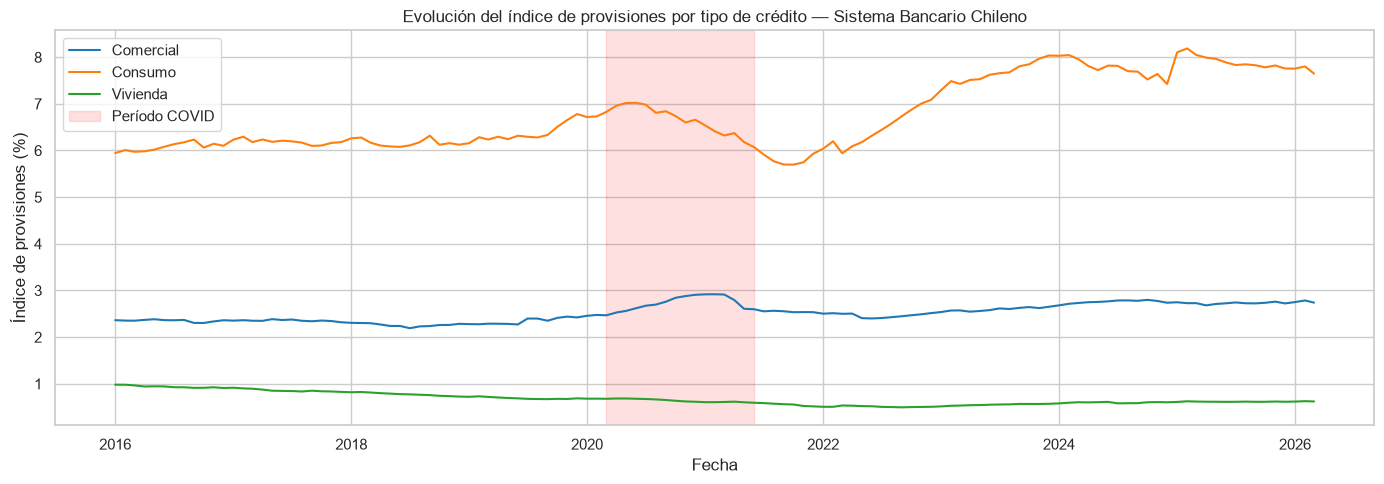

In [6]:
sistema = df_sis

fig, ax = plt.subplots()
ax.plot(sistema['fecha'], sistema['indice_comercial'], label='Comercial')
ax.plot(sistema['fecha'], sistema['indice_consumo'],   label='Consumo')
ax.plot(sistema['fecha'], sistema['indice_vivienda'],  label='Vivienda')

# Marcamos COVID
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-06-01'),
           alpha=0.12, color='red', label='Período COVID')

ax.set_title('Evolución del índice de provisiones por tipo de crédito — Sistema Bancario Chileno')
ax.set_xlabel('Fecha')
ax.set_ylabel('Índice de provisiones (%)')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Comparativa entre bancos — índice promedio por tipo de crédito

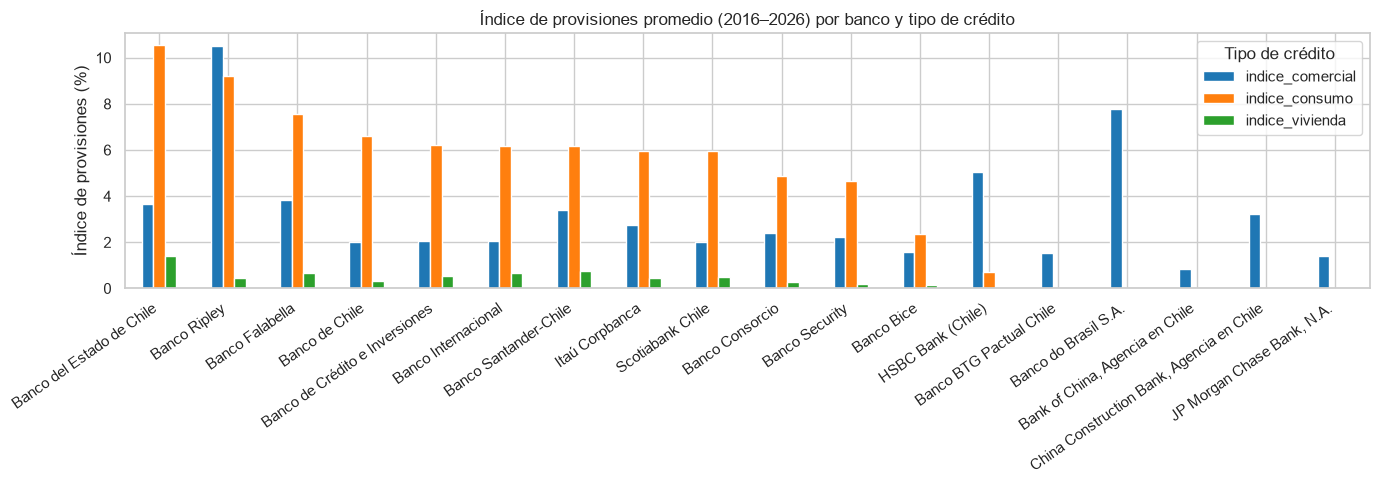

In [7]:
# Solo bancos con presencia significativa (al menos 60 meses de datos)
bancos_principales = resumen_bancos[resumen_bancos['meses'] >= 60].index.tolist()

prom_banco = (
    df_prov[df_prov['banco'].isin(bancos_principales)]
    .groupby('banco')[['indice_comercial', 'indice_consumo', 'indice_vivienda']]
    .mean()
    .round(2)
    .sort_values('indice_consumo', ascending=False)
)

prom_banco.plot(kind='bar', figsize=(14, 5))
plt.title('Índice de provisiones promedio (2016–2026) por banco y tipo de crédito')
plt.ylabel('Índice de provisiones (%)')
plt.xlabel('')
plt.xticks(rotation=35, ha='right')
plt.legend(title='Tipo de crédito')
plt.tight_layout()
plt.show()

## 4. Evolución por banco — créditos de consumo
El crédito de consumo es el que más refleja el riesgo minorista.

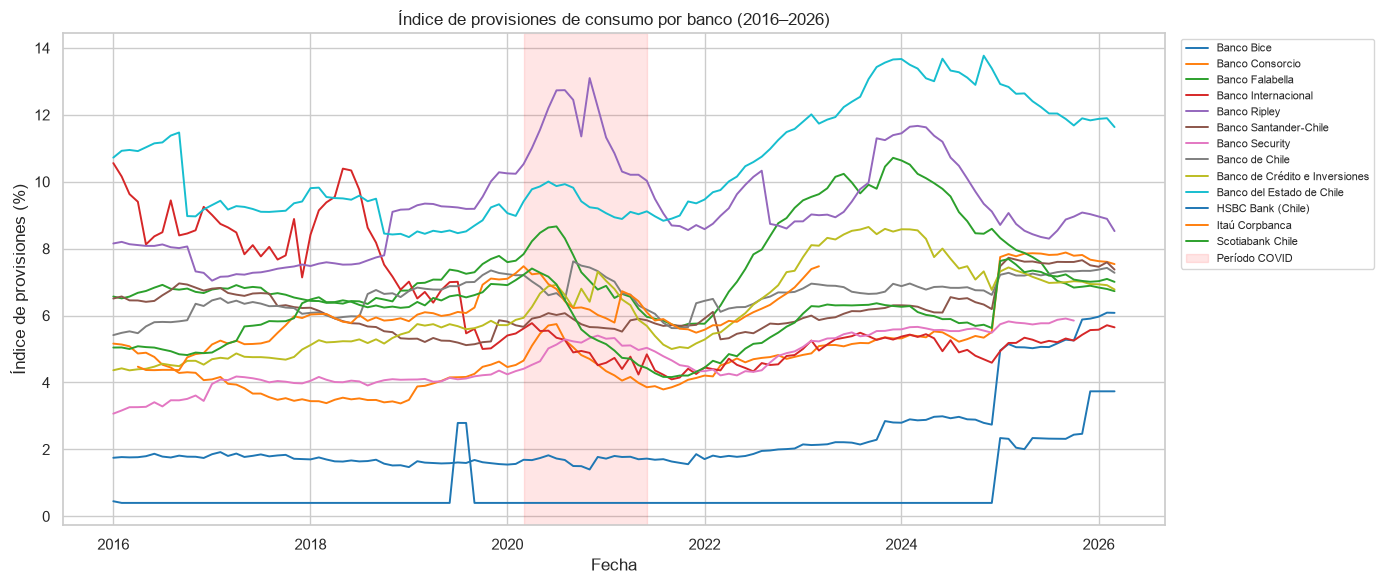

In [8]:
df_consumo = df_prov[df_prov['banco'].isin(bancos_principales)][['fecha', 'banco', 'indice_consumo']].dropna()

fig, ax = plt.subplots(figsize=(14, 6))
for banco, grupo in df_consumo.groupby('banco'):
    ax.plot(grupo['fecha'], grupo['indice_consumo'], label=banco, linewidth=1.4)

ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-06-01'),
           alpha=0.1, color='red', label='Período COVID')

ax.set_title('Índice de provisiones de consumo por banco (2016–2026)')
ax.set_ylabel('Índice de provisiones (%)')
ax.set_xlabel('Fecha')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

## 5. Calidad de cartera — evolución por clasificación

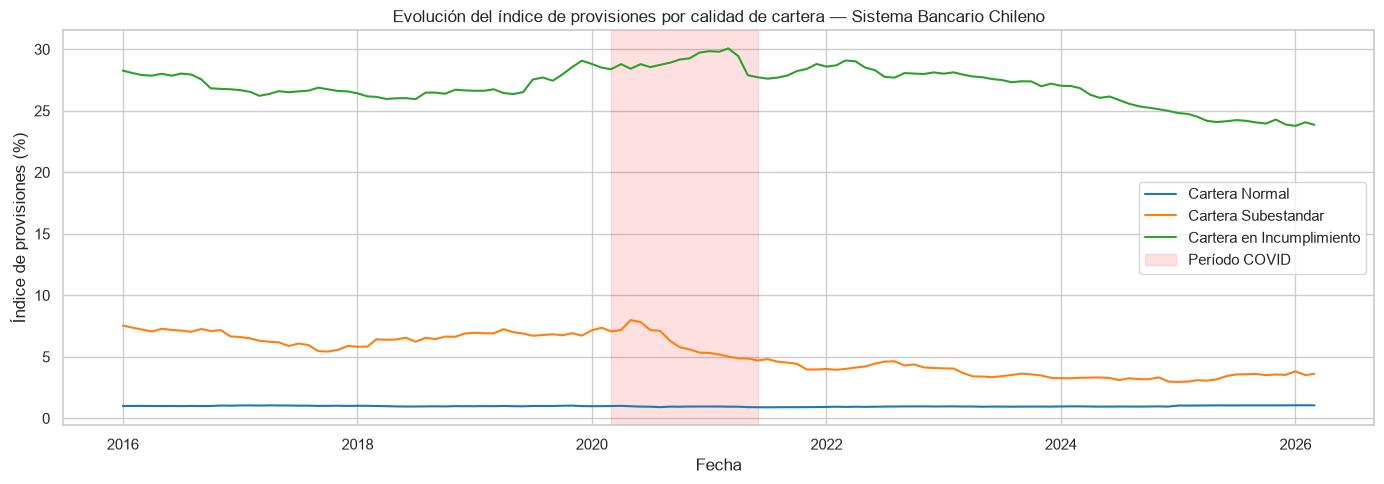

In [9]:
sistema_cart = df_cart_sis

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sistema_cart['fecha'], sistema_cart['indice_cartera_normal'],        label='Cartera Normal')
ax.plot(sistema_cart['fecha'], sistema_cart['indice_cartera_subestandar'],   label='Cartera Subestandar')
ax.plot(sistema_cart['fecha'], sistema_cart['indice_cartera_incumplimiento'],label='Cartera en Incumplimiento')

ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-06-01'),
           alpha=0.12, color='red', label='Período COVID')

ax.set_title('Evolución del índice de provisiones por calidad de cartera — Sistema Bancario Chileno')
ax.set_ylabel('Índice de provisiones (%)')
ax.set_xlabel('Fecha')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Heatmap — índice de consumo por banco y año

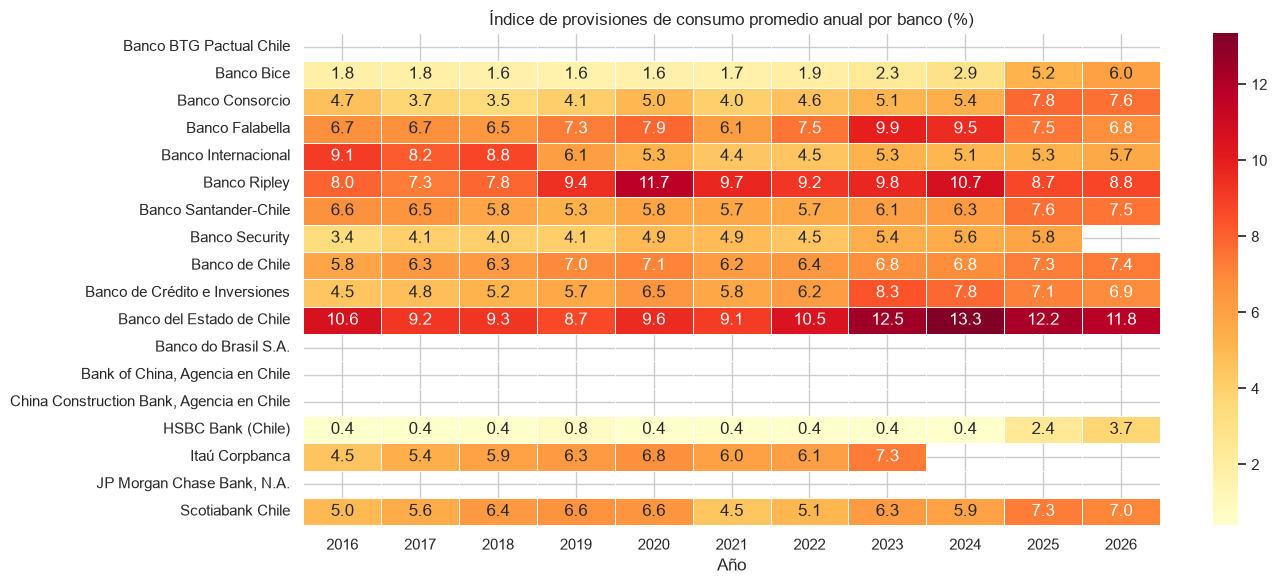

In [10]:
df_heat = df_prov[df_prov['banco'].isin(bancos_principales)].copy()
df_heat['anio'] = df_heat['fecha'].dt.year

pivot = (
    df_heat.groupby(['banco', 'anio'])['indice_consumo']
    .mean()
    .unstack()
    .round(2)
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5, ax=ax)
ax.set_title('Índice de provisiones de consumo promedio anual por banco (%)')
ax.set_ylabel('')
ax.set_xlabel('Año')
plt.tight_layout()
plt.show()

## 7. Distribución de índices por tipo de crédito

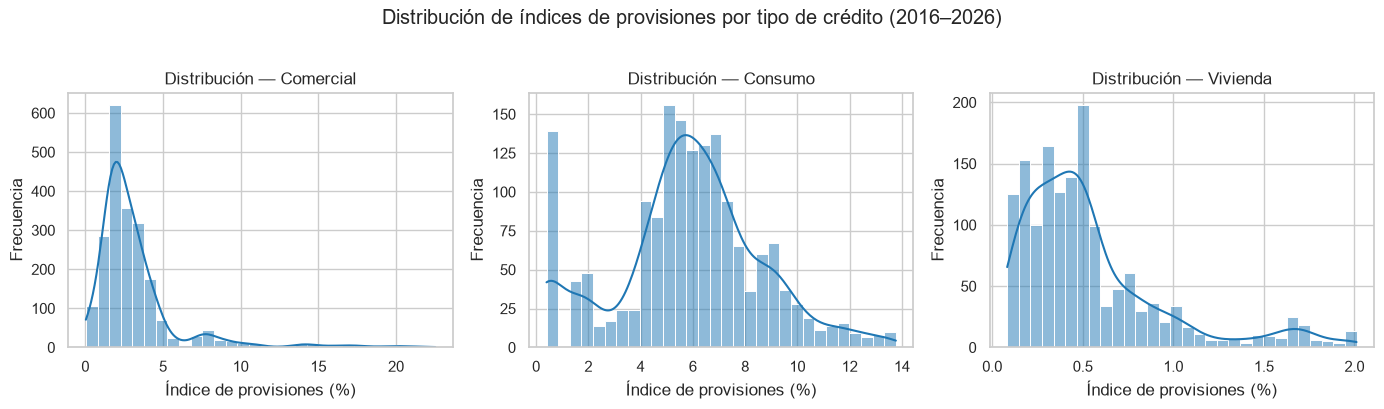

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col, titulo in zip(axes,
    ['indice_comercial', 'indice_consumo', 'indice_vivienda'],
    ['Comercial', 'Consumo', 'Vivienda']):
    
    data = df_prov[col].dropna()
    sns.histplot(data, bins=30, kde=True, ax=ax)
    ax.set_title(f'Distribución — {titulo}')
    ax.set_xlabel('Índice de provisiones (%)')
    ax.set_ylabel('Frecuencia')

plt.suptitle('Distribución de índices de provisiones por tipo de crédito (2016–2026)', y=1.02)
plt.tight_layout()
plt.show()

## 8. Resumen estadístico por banco

In [12]:
resumen_final = (
    df_prov[df_prov['banco'].isin(bancos_principales)]
    .groupby('banco')[['indice_comercial', 'indice_consumo', 'indice_vivienda']]
    .agg(['mean', 'std', 'min', 'max'])
    .round(2)
)
resumen_final

indice_comercial                     \
                                                      mean   std   min    max   
banco                                                                           
Banco BTG Pactual Chile                               1.53  0.85  0.17   3.09   
Banco Bice                                            1.56  0.26  1.24   2.39   
Banco Consorcio                                       2.41  0.58  1.46   3.63   
Banco Falabella                                       3.81  0.59  2.67   4.82   
Banco Internacional                                   2.04  0.50  1.44   3.23   
Banco Ripley                                         10.51  5.73  1.35  22.52   
Banco Santander-Chile                                 3.39  0.27  3.03   4.23   
Banco Security                                        2.22  0.60  1.43   3.36   
Banco de Chile                                        2.01  0.18  1.77   2.52   
Banco de Crédito e Inversiones                        2.04  0.20  1.74   2.61   
Banco del Estado de Chile                             3.65  0.57  2.76   4.69   
Banco do Brasil S.A.                                  7.76  3.45  1.26  15.93   
Bank of China, Agencia en Chile                       0.83  1.19  0.22   4.28   
China Construction Bank, Agencia en Chile             3.24  2.92  0.61   9.40   
HSBC Bank (Chile)                                     5.04  1.56  3.30  10.88   
Itaú Corpbanca                                        2.73  0.61  1.61   4.28   
JP Morgan Chase Bank, N.A.                            1.40  1.85  0.04   9.00   
Scotiabank Chile                                      2.03  0.32  1.50   2.67   

                                          indice_consumo                     \
                                                    mean   std   min    max   
banco                                                                         
Banco BTG Pactual Chile                              NaN   NaN   NaN    NaN   
Banco Bice                                          2.34  1.22  1.40   6.09   
Banco Consorcio                                     4.86  1.26  3.37   7.88   
Banco Falabella                                     7.54  1.31  5.67  10.72   
Banco Internacional                                 6.19  1.77  4.09  10.56   
Banco Ripley                                        9.22  1.43  7.04  13.10   
Banco Santander-Chile                               6.18  0.68  5.12   7.73   
Banco Security                                      4.64  0.77  3.07   5.91   
Banco de Chile                                      6.62  0.52  5.42   7.62   
Banco de Crédito e Inversiones                      6.21  1.26  4.36   8.65   
Banco del Estado de Chile                          10.53  1.65  8.35  13.77   
Banco do Brasil S.A.                                 NaN   NaN   NaN    NaN   
Bank of China, Agencia en Chile                      NaN   NaN   NaN    NaN   
China Construction Bank, Agencia en Chile            NaN   NaN   NaN    NaN   
HSBC Bank (Chile)                                   0.72  0.83  0.40   3.74   
Itaú Corpbanca                                      5.95  0.76  4.37   7.47   
JP Morgan Chase Bank, N.A.                           NaN   NaN   NaN    NaN   
Scotiabank Chile                                    5.94  0.90  4.16   7.69   

                                          indice_vivienda                    
                                                     mean   std   min   max  
banco                                                                        
Banco BTG Pactual Chile                               NaN   NaN   NaN   NaN  
Banco Bice                                           0.13  0.03  0.08  0.20  
Banco Consorcio                                      0.28  0.15  0.12  0.63  
Banco Falabella                                      0.68  0.24  0.41  1.22  
Banco Internacional                                  0.66  0.54  0.17  1.90  
Banco Ripley                                         0.4

## 9. Conclusiones

### Hallazgos principales

**1. COVID: alza inicial y luego caída**  
El índice de provisiones de consumo del sistema pasó de un promedio de **6.22%** en el período pre-COVID (ene. 2016 – feb. 2020) a un peak de **7.02%** a mediados de 2020. Luego cayó hasta **5.70%** en septiembre–octubre 2021, el mínimo de la serie, en coincidencia con los retiros de fondos de pensiones y las ayudas estatales que dieron liquidez a los hogares. El índice comercial, en cambio, subió de 2.33% a un peak de 2.92% a inicios de 2021.

**2. Post-pandemia, el riesgo de consumo superó los niveles previos**  
Desde 2022 el índice de consumo promedia **7.47%**, más de un punto sobre el nivel pre-pandemia. 2025 cerró con **7.92%**, el promedio anual más alto del período, con un peak mensual de **8.19%** en febrero 2025.

**3. BancoEstado lidera el riesgo de consumo**  
Con un índice promedio de **10.53%**, BancoEstado supera a los bancos de retail: Banco Ripley (**9.22%**) y Banco Falabella (**7.54%**). Es consistente con su foco en segmentos masivos de personas.

**4. Banco de Chile tiene la cartera de consumo más estable**  
Su índice de consumo se movió en un rango de solo **2.2 puntos** (5.42% – 7.62%) y tiene la menor desviación estándar (0.52) entre los bancos con historia completa. Le sigue Santander (2.6 puntos).

**5. El crédito de vivienda es el tipo de menor riesgo**  
En el **100%** de los meses y bancos analizados, el índice de vivienda está por debajo de comercial y consumo, consistente con el respaldo hipotecario de la deuda. En el sistema bajó de 0.94% (2016) a 0.62% (2026).

**6. Divergencia reciente entre bancos**  
Banco Falabella bajó de **10.72%** (dic. 2023) a **6.73%** (mar. 2026), quedando por debajo de Banco de Chile (7.28%), y BancoEstado bajó de **13.77%** (nov. 2024) a **11.64%**. En el mismo período, Banco de Chile subió de 6.44% (promedio 2022) a 7.36% (promedio 2026).

---
*Nota: Los índices corresponden a provisiones por riesgo de crédito sobre colocaciones, expresados en porcentaje. Un índice más alto no implica necesariamente peor gestión: también refleja políticas de provisiones más prudentes y cambios normativos. Fuente: CMF Chile.*